In [28]:
import pandas as pd 
import geopandas as gpd
URL = ('https://raw.githubusercontent.com/carmengg/eds220-hwk-1/main/data/earthquake_data.csv')
earthquakes = pd.read_csv(URL)

countries = gpd.read_file('data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')
import matplotlib.pyplot as plt

In [29]:
earthquakes.head()

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ak11151135,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ci37171541,"10km WNW of Progreso, Mexico",earthquake


In [30]:
countries.head(2)

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."


In [31]:
earthquakes_mags = earthquakes[earthquakes['mag']>=6.5]
earthquakes_mags

,time,latitude,longitude,depth,mag,id,place,type
9062,2014-01-01 16:03:29.000,-13.8633,167.2490,187.00,6.5,usc000lvb5,"32km W of Sola, Vanuatu",earthquake
12142,2014-02-18 09:27:13.120,14.6682,-58.9272,14.83,6.5,usc000mskt,"172km NNE of Bathsheba, Barbados",earthquake
14025,2014-02-12 09:19:49.060,35.9053,82.5864,10.00,6.9,usc000mnvj,"272km ESE of Hotan, China",earthquake
15979,2014-02-07 08:40:13.550,-15.0691,167.3721,122.00,6.5,usc000mjye,"34km E of Port-Olry, Vanuatu",earthquake
17606,2014-02-02 09:26:37.820,-32.9076,-177.8806,44.26,6.5,usc000mfm0,"189km SSE of L'Esperance Rock, New Zealand",earthquake
22968,2014-03-16 21:16:29.600,-19.9807,-70.7022,20.00,6.7,usc000ndnj,"64km WNW of Iquique, Chile",earthquake
24887,2014-03-10 05:18:13.400,40.8287,-125.1338,16.60,6.8,nc72182046,"78km WNW of Ferndale, California",earthquake
26972,2014-03-02 20:11:23.430,27.4312,127.3674,119.00,6.5,usb000mzmn,"111km NNW of Nago, Japan",earthquake
29890,2014-04-24 03:10:10.150,49.6388,-127.7316,10.00,6.5,usb000px6r,"120km S of Port Hardy, Canada",earthquake
31496,2014-04-19 13:28:00.810,-6.7547,155.0241,43.37,7.5,usb000pr89,"70km SW of Panguna, Papua New Guinea",earthquake


In [45]:
points = gpd.points_from_xy(earthquakes_mags['longitude'], earthquakes_mags['latitude'])
earthquakes_mags = gpd.GeoDataFrame(earthquakes_mags, geometry=points, crs='EPSG:4326')

Text(0.5, 88.64025169067803, 'Longitude')

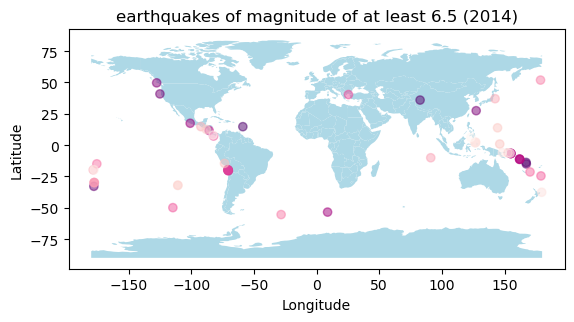

In [50]:
fig, ax = plt.subplots()
countries.plot(ax=ax, 
               color='lightblue')
earthquakes_mags.plot(ax=ax, 
                      alpha = 0.5,  
                      c =  'mag', 
                      cmap='RdPu_r')

ax.set_title('earthquakes of magnitude of at least 6.5 (2014)')
ax.set_ylabel('Latitude')
ax.set_xlabel('Longitude')